# MONAI

## Check GPU

In [55]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA compiled:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: C:\Users\user\anaconda3\envs\monai\python.exe
PyTorch: 2.11.0+cu128
CUDA compiled: 12.8
CUDA available: True
GPU: NVIDIA GeForce RTX 5070


## Imports

In [56]:
import logging
import numpy as np
import os
from pathlib import Path
import sys
import tempfile
import torch
import ignite

from monai.apps import MedNISTDataset
from monai.config import print_config
from monai.data import DataLoader
from monai.engines import SupervisedTrainer, SupervisedEvaluator
from monai.handlers import (
    StatsHandler,
    TensorBoardStatsHandler,
    ValidationHandler,
    CheckpointSaver,
    CheckpointLoader,
    ClassificationSaver,
)
from monai.handlers.utils import from_engine
from monai.inferers import SimpleInferer
from monai.networks.nets import densenet121
from monai.transforms import LoadImageD, EnsureChannelFirstD, ScaleIntensityD, Compose, AsDiscreted
from monai.data import Dataset
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Resized,
    ScaleIntensityd,
    EnsureTyped,
)

print_config()

MONAI version: 1.6.0
Numpy version: 1.26.4
Pytorch version: 2.11.0+cu128
MONAI flags: HAS_EXT = False, USE_COMPILED = False, USE_META_DICT = False
MONAI rev id: eccefc57550b111ed781d82249dfe77872a0e918
MONAI __file__: C:\Users\<username>\anaconda3\envs\monai\lib\site-packages\monai\__init__.py

Optional dependencies:
Pytorch Ignite version: NOT INSTALLED or UNKNOWN VERSION.
ITK version: NOT INSTALLED or UNKNOWN VERSION.
Nibabel version: 5.4.2
scikit-image version: NOT INSTALLED or UNKNOWN VERSION.
scipy version: NOT INSTALLED or UNKNOWN VERSION.
Pillow version: 12.3.0
Tensorboard version: 2.21.0
gdown version: NOT INSTALLED or UNKNOWN VERSION.
TorchVision version: 0.26.0+cu128
tqdm version: NOT INSTALLED or UNKNOWN VERSION.
lmdb version: NOT INSTALLED or UNKNOWN VERSION.
psutil version: 7.2.2
pandas version: NOT INSTALLED or UNKNOWN VERSION.
einops version: NOT INSTALLED or UNKNOWN VERSION.
transformers version: NOT INSTALLED or UNKNOWN VERSION.
mlflow version: NOT INSTALLED or UNKNOWN

## Loading Dataset

In [57]:
DATA_DIR = Path(
    r"C:\Users\user\Desktop\MONAI\data\brain-tumor-mri-classification\merged_dataset_v3\images"
)

In [58]:
class_names = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary",
]

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

In [59]:
def get_image_files(split):
    split_dir = DATA_DIR / split
    data = []

    for class_name in class_names:
        class_dir = split_dir / class_name

        for image_path in class_dir.iterdir():
            if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                data.append(
                    {
                        "image": str(image_path),
                        "label": class_to_idx[class_name],
                    }
                )

    return data

In [60]:
transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    Resized(keys=["image"], spatial_size=(224, 224)),
    ScaleIntensityd(keys=["image"]),
    EnsureTyped(keys=["image"]),
])

In [61]:
train_files = get_image_files("train")
val_files = get_image_files("val")
test_files = get_image_files("test")

In [62]:
train_dataset = Dataset(
    data=train_files,
    transform=transforms,
)

val_dataset = Dataset(
    data=val_files,
    transform=transforms,
)

test_dataset = Dataset(
    data=test_files,
    transform=transforms,
)

In [63]:
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

print("First sample:", train_dataset[0])

Train images: 8306
Validation images: 488
Test images: 246
First sample: {'image': metatensor([[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0041, 0.0041, 0.0041],
         [0.0000, 0.0000, 0.0000,  ..., 0.0123, 0.0123, 0.0123],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0082, 0.0041, 0.0041],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0041]],

        [[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0041, 0.0041, 0.0041],
         [0.0000, 0.0000, 0.0000,  ..., 0.0123, 0.0123, 0.0123],
         ...,
         [0.0000, 0.0000, 0.0000,  ..., 0.0082, 0.0041, 0.0041],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0041]],

        [[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000,  .

In [64]:
sample = train_dataset[0]

print(type(sample))
print(sample.keys())

<class 'dict'>
dict_keys(['image', 'label'])


In [65]:
print("Image Type :", type(sample["image"]))
print("Image Shape:", sample["image"].shape)
print("Image dtype:", sample["image"].dtype)
print("Label:", sample["label"])

Image Type : <class 'monai.data.meta_tensor.MetaTensor'>
Image Shape: torch.Size([3, 224, 224])
Image dtype: torch.float32
Label: 0


## Plot class distribution

In [66]:
import matplotlib.pyplot as plt
from collections import Counter
import random

Training Dataset Distribution
glioma       : 2183 images
meningioma   : 1912 images
no_tumor     : 2044 images
pituitary    : 2167 images


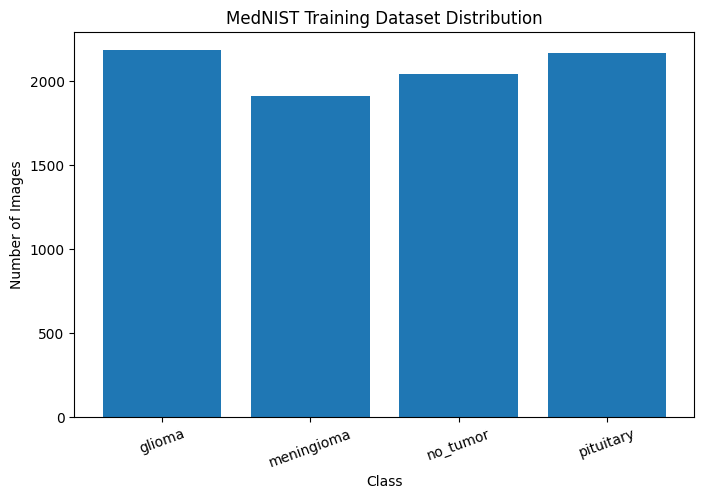

In [67]:
labels = [train_dataset[i]["label"] for i in range(len(train_dataset))]
label_counts = Counter(labels)

print("=" * 50)
print("Training Dataset Distribution")
print("=" * 50)

for idx, name in enumerate(class_names):
    print(f"{name:<12} : {label_counts[idx]} images")

plt.figure(figsize=(8,5))
plt.bar(class_names, [label_counts[i] for i in range(len(class_names))])

plt.title("MedNIST Training Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)

plt.show()

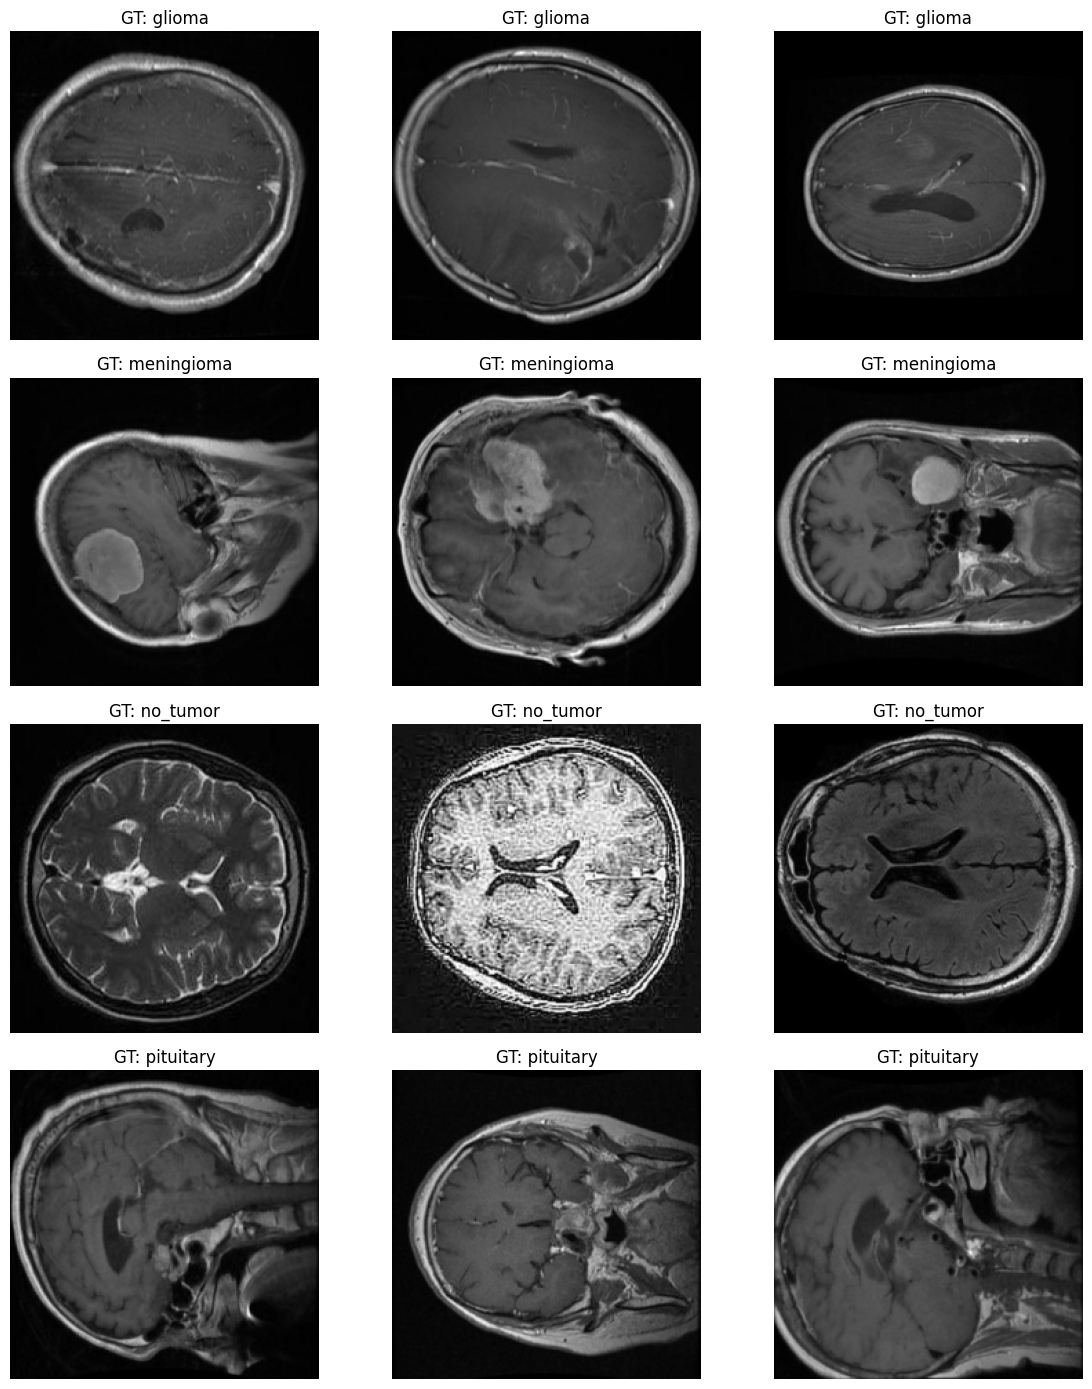

In [68]:
samples_per_class = 3

fig, axes = plt.subplots(len(class_names), samples_per_class,
                         figsize=(12, 14))

for class_id in range(len(class_names)):

    # Find indices belonging to this class
    indices = [i for i in range(len(train_dataset))
               if train_dataset[i]["label"] == class_id]

    # Randomly select images
    chosen = random.sample(indices, samples_per_class)

    for j, idx in enumerate(chosen):

        sample = train_dataset[idx]

        axes[class_id, j].imshow(sample["image"][0], cmap="gray")
        axes[class_id, j].set_title(f"GT: {class_names[class_id]}")
        axes[class_id, j].axis("off")

plt.tight_layout()
plt.show()

In [69]:
loss_fn = torch.nn.CrossEntropyLoss()

train_metrics = {
    "train_accuracy": ignite.metrics.Accuracy(
        output_transform=from_engine(["pred", "label"])
    ),
}

val_metrics = {
    "val_accuracy": ignite.metrics.Accuracy(
        output_transform=from_engine(["pred", "label"])
    ),
    "val_loss": ignite.metrics.Loss(
        loss_fn=loss_fn,
        output_transform=from_engine(["pred", "label"]),
    ),
}

In [70]:
from torch.utils.data import Subset
import random

random.seed(42)

train_indices = random.sample(
    range(len(train_dataset)),
    min(500, len(train_dataset))
)

val_indices = random.sample(
    range(len(val_dataset)),
    min(500, len(val_dataset))
)

test_indices = random.sample(
    range(len(test_dataset)),
    min(500, len(test_dataset))
)

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)
test_subset = Subset(test_dataset, test_indices)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:", len(test_subset))

Training images: 500
Validation images: 488
Test images: 246


In [71]:
max_epochs = 1
save_interval = 2
out_dir = "./eval"

device = torch.device("cuda:0")

model = densenet121(
    spatial_dims=2,
    in_channels=3,   # Use 1 if your images are actually grayscale
    out_channels=4,  # glioma, meningioma, no_tumor, pituitary
).to(device)

loss_fn = torch.nn.CrossEntropyLoss()

logging.basicConfig(
    stream=sys.stdout,
    level=logging.INFO,
)

# --------------------------------------------------
# VALIDATION METRICS
# --------------------------------------------------

evaluator = SupervisedEvaluator(
    device=device,
    val_data_loader=DataLoader(
        val_dataset,
        batch_size=512,
        shuffle=False,
        num_workers=0,
    ),
    network=model,
    inferer=SimpleInferer(),
    key_val_metric={
        "val_accuracy": ignite.metrics.Accuracy(
            output_transform=from_engine(["pred", "label"])
        ),

        "val_loss": ignite.metrics.Loss(
            loss_fn=loss_fn,
            output_transform=from_engine(["pred", "label"]),
        ),
    },

    val_handlers=[
        StatsHandler(
            iteration_log=False,
        ),

        TensorBoardStatsHandler(
            iteration_log=False,
            tag_name="validation",
        ),
    ],
)

# --------------------------------------------------
# TRAINING
# --------------------------------------------------

trainer = SupervisedTrainer(
    device=device,
    max_epochs=max_epochs,

    train_data_loader=DataLoader(
        train_subset,
        batch_size=32,
        shuffle=True,
        num_workers=0,
    ),

    network=model,

    optimizer=torch.optim.Adam(
        model.parameters(),
        lr=1e-5,
    ),

    loss_function=loss_fn,
    inferer=SimpleInferer(),

    key_train_metric={
        "train_accuracy": ignite.metrics.Accuracy(
            output_transform=from_engine(["pred", "label"])
        ),
    },

    train_handlers=[
        ValidationHandler(
            validator=evaluator,
            epoch_level=True,
            interval=1,
        ),

        CheckpointSaver(
            save_dir=out_dir,
            save_dict={"model": model},
            save_interval=save_interval,
            save_final=True,
            final_filename="checkpoint.pt",
        ),

        StatsHandler(),

        TensorBoardStatsHandler(
            tag_name="train",
            output_transform=from_engine(
                ["loss"],
                first=True,
            ),
        ),
    ],
)

In [72]:
from ignite.engine import Events

@trainer.on(Events.EPOCH_COMPLETED)
def log_epoch_metrics(engine):
    epoch = engine.state.epoch

    train_accuracy = engine.state.metrics.get("train_accuracy")
    train_loss = engine.state.metrics.get("loss")

    val_accuracy = evaluator.state.metrics.get("val_accuracy")
    val_loss = evaluator.state.metrics.get("val_loss")

    print(
        f"\nEpoch {epoch}/{max_epochs}\n"
        f"Train Accuracy: {train_accuracy}\n"
        f"Train Loss: {train_loss}\n"
        f"Val Accuracy: {val_accuracy}\n"
        f"Val Loss: {val_loss}\n"
    )

In [73]:
trainer.run()

INFO:ignite.engine.engine.SupervisedTrainer:Engine run resuming from iteration 0, epoch 0 until 1 epochs
2026-09-14 21:50:14,170 - INFO - Epoch: 1/1, Iter: 1/16 -- label: 2.0000 loss: 1.4690 
2026-09-14 21:50:14,387 - INFO - Epoch: 1/1, Iter: 2/16 -- label: 0.0000 loss: 1.4151 
2026-09-14 21:50:14,599 - INFO - Epoch: 1/1, Iter: 3/16 -- label: 1.0000 loss: 1.3883 
2026-09-14 21:50:14,823 - INFO - Epoch: 1/1, Iter: 4/16 -- label: 3.0000 loss: 1.3553 
2026-09-14 21:50:15,037 - INFO - Epoch: 1/1, Iter: 5/16 -- label: 3.0000 loss: 1.3358 
2026-09-14 21:50:15,251 - INFO - Epoch: 1/1, Iter: 6/16 -- label: 3.0000 loss: 1.3737 
2026-09-14 21:50:15,454 - INFO - Epoch: 1/1, Iter: 7/16 -- label: 2.0000 loss: 1.4773 
2026-09-14 21:50:15,658 - INFO - Epoch: 1/1, Iter: 8/16 -- label: 0.0000 loss: 1.3670 
2026-09-14 21:50:15,884 - INFO - Epoch: 1/1, Iter: 9/16 -- label: 0.0000 loss: 1.2845 
2026-09-14 21:50:16,093 - INFO - Epoch: 1/1, Iter: 10/16 -- label: 0.0000 loss: 1.3224 
2026-09-14 21:50:16,298 

In [80]:
import torch
from monai.data import DataLoader

test_loader = DataLoader(
    test_subset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
)

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in test_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        logits = model(images)

        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = correct / total

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 34.96%


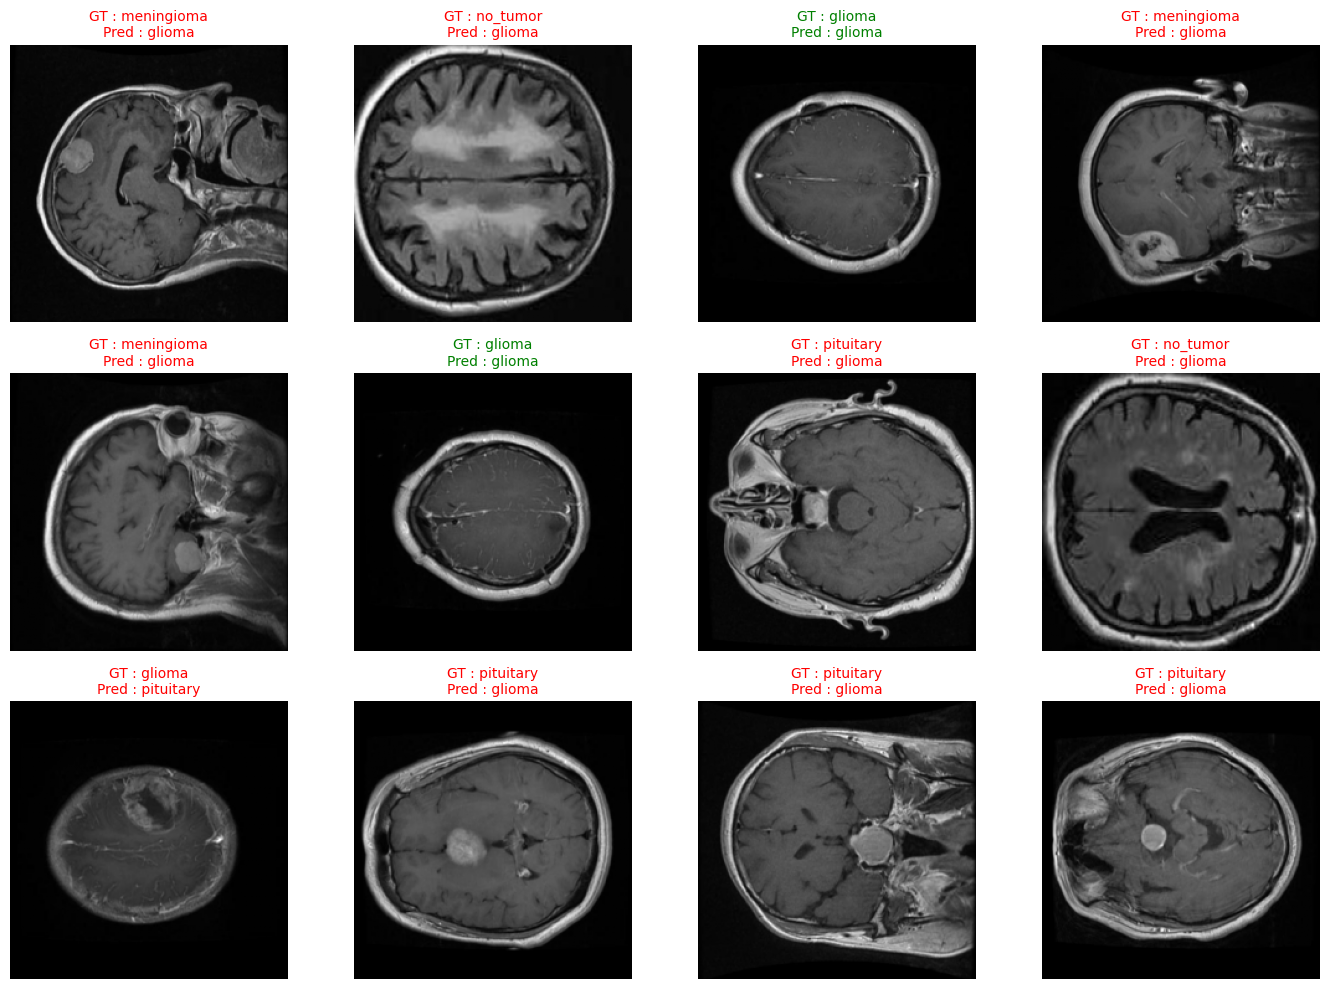

In [81]:
import matplotlib.pyplot as plt
import torch
import random

model.eval()

device = torch.device("cuda:0")

num_images = 12

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax in axes.flat:

    idx = random.randint(0, len(test_dataset)-1)

    sample = test_dataset[idx]

    image = sample["image"].unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image)
        pred = torch.argmax(output, dim=1).item()

    gt = sample["label"]

    ax.imshow(sample["image"][0], cmap="gray")

    color = "green" if pred == gt else "red"

    ax.set_title(
        f"GT : {class_names[gt]}\nPred : {class_names[pred]}",
        color=color,
        fontsize=10,
    )

    ax.axis("off")

plt.tight_layout()
plt.show()